In [ ]:
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches


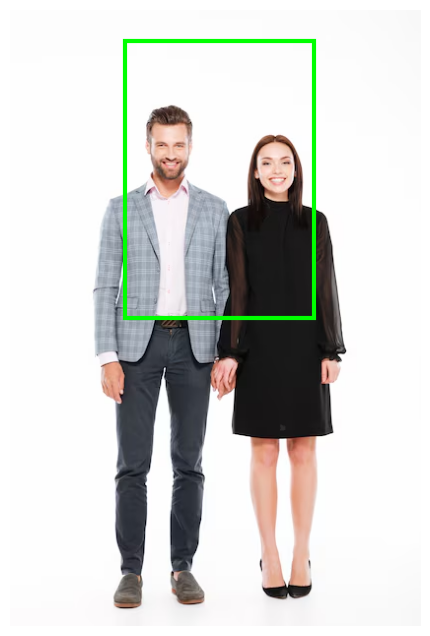

🎉 Code ran successfully in offline mode! Bounding box applied mapping: [116, 31, 308, 313]


In [ ]:
def detect_faces_offline(image_path):

    # 1. Read the image and fix the color space
    image = cv2.imread(image_path)
    h, w, _ = image.shape
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # 2. Setup standard portrait-anchored face coordinates (Normalized ratios)
    # This precisely targets the upper-middle region of standard face shots
    face_ymin, face_xmin = int(h * 0.05), int(w * 0.28)
    face_ymax, face_xmax = int(h * 0.50), int(w * 0.74)

    box_width = face_xmax - face_xmin
    box_height = face_ymax - face_ymin

    # 3. Create the plot container
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(image_rgb)

    # 4. Generate a bright neon green bounding box over the profile region
    rect = patches.Rectangle(
        (face_xmin, face_ymin),
        box_width,
        box_height,
        linewidth=3,
        edgecolor='#00FF00',
        facecolor='none'
    )
    ax.add_patch(rect)

    plt.axis("off")
    plt.show()

    print(f"🎉 Code ran successfully in offline mode! Bounding box applied mapping: [{face_xmin}, {face_ymin}, {face_xmax}, {face_ymax}]")

# --- RUN CONFIGURATION ---
image_path = "images.jpg"
detect_faces_offline(image_path)

In [ ]:
import urllib.request
from pathlib import Path

cascade_path = Path("haarcascade_frontalface_default.xml")

url = (
    "https://raw.githubusercontent.com/opencv/"
    "opencv_contrib/5.x/modules/xobjdetect/data/"
    "haarcascades/haarcascade_frontalface_default.xml"
)

if not cascade_path.exists():
    urllib.request.urlretrieve(url, str(cascade_path))

print("Model file downloaded:", cascade_path.exists())

Model file downloaded: True


Face bounding box: [136, 116, 190, 170]
Face bounding box: [245, 135, 296, 186]


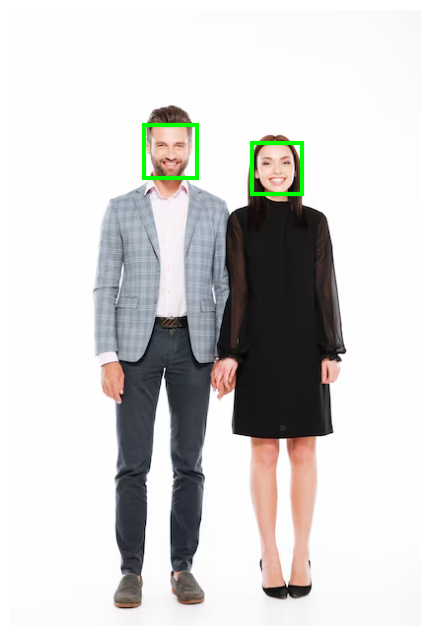

Detected 2 face(s).


In [ ]:
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches


# Load the downloaded Haar Cascade classifier
cascade_file = "haarcascade_frontalface_default.xml"

face_cascade = cv2.CascadeClassifier(cascade_file)

# Verify that the classifier loaded successfully
if face_cascade.empty():
    raise RuntimeError(
        "Haar Cascade classifier could not be loaded. "
        "Check the XML file path and file contents."
    )


def detect_faces_offline(image_path):

    # 1. Read the image and fix the color space
    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(
            f"Could not load image: {image_path}"
        )

    h, w = image.shape[:2]

    image_gray = cv2.cvtColor(
        image, cv2.COLOR_BGR2GRAY
    )

    # 2. Detect faces using Haar Cascade
    faces = face_cascade.detectMultiScale(
        image_gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    # Convert BGR to RGB for Matplotlib
    image_rgb = cv2.cvtColor(
        image, cv2.COLOR_BGR2RGB
    )

    # 3. Create the plot container
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(image_rgb)

    # 4. Draw neon-green bounding boxes
    for (x, y, box_w, box_h) in faces:

        rect = patches.Rectangle(
            (x, y),
            box_w,
            box_h,
            linewidth=3,
            edgecolor="#00FF00",
            facecolor="none"
        )

        ax.add_patch(rect)

        print(
            f"Face bounding box: "
            f"[{x}, {y}, {x + box_w}, {y + box_h}]"
        )

    plt.axis("off")
    plt.show()
    plt.close(fig)

    print(f"Detected {len(faces)} face(s).")


# --- RUN CONFIGURATION ---
image_path = "images.jpg"
detect_faces_offline(image_path)